## Classificação

## Regressão

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Define uma semente de aleatoriedade, permitindo que o experimento
# possa ser replicado com os mesmos valores
SEED = 12

#===================================================================

# Quantidade de amostras
samples = 200

# Define uma instância de aleatoriedade
rng = np.random.default_rng(seed = SEED)

# DefiGerane valores aleatórios entre 0 e 2π e ordena eles
x = np.sort(rng.random(samples) * np.pi * 2)

# Definindo o comportamento da curva em função de x
y = 2 * np.sin(x) + np.sin(3 * x) + rng.normal(
	loc = 0, scale = 0.1, size = len(x)
)

# Criando a tabela
df = pd.DataFrame(data = zip(x, y), columns = ['x', 'y'])

#===================================================================
# Cria um gráfico apresentando o comportamento da função criada

# Define um título
plt.title(label = "f(x) = cos(x) + normal distribution")

# Cria o gráfico de dispersão
plt.scatter(df['x'], df['y'], s = 5)

# Define rótulos para os eixos x e y
plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')

# Cria linhas de grade
plt.grid(alpha = 0.3, ls = '--')

# Deixa o gráfico mais enxuto removendo partes brancas
plt.tight_layout()
plt.show()

#===================================================================

def criador_medias(df: pd.DataFrame):
    """
    Com base em um array, faz a média entre os elementos.

    Por exemplo:
        entrada: [1, 2, 4, 8, 10, 11]
        saída: [1.5, 3, 6, 9, 10.5]
    """
    if df.shape[0] > 1:
        df['x1'] = df['x'].shift(-1)
        df = df.dropna()
        df['media_valores_x'] = (df['x'] + df['x1']) / 2
    else:
        raise ValueError("Não há como calcular a média já que só há um único valor")
    return df['media_valores_x'].values


def calcula_indice_impureza(df: pd.DataFrame, n_total: int, tipo_impureza: str = 'sse'):
    """
    Calcula a média dos erros quadráticos (MSE) ou soma dos erros quadráticos (SSE).
    """
    # Ponderação da quantidade de amostras
    percentual = df.shape[0] / n_total

    if tipo_impureza == 'sse':
        return ((df['y'] - df['y'].mean()) ** 2).sum()
    elif tipo_impureza == 'mse':
        return ((df['y']  - df['y'].mean()) ** 2).mean() * percentual
    else:
        raise ValueError(f"{tipo_impureza} é inválido, escolha entre 'sse' ou 'mse'.")


def calcular_tabela(df: pd.DataFrame):
    """
    Cria uma tabela com os principais dados para a geração de um nó.

    É importante destacar que a tabela é filtrada para o melhor caso, isto é,
    onde a soma do SSE da esquerda e da direita é a menor possível em relação as
    outras combinações.

    media: Média do x entre os os valores do x. Isto é, o melhor ponto de quebra do
    atributo x
    
    """
    resultados = []

    if df.shape[0] > 1:
        for i in criador_medias(df):
            esquerda = df[df['x'] <= i]
            direita = df[df['x'] > i]

            # Quantidade total de elementos
            n_total = df.shape[0]

            if not esquerda.empty:
                sse_esquerda = calcula_indice_impureza(esquerda, n_total = n_total, tipo_impureza = 'mse')
                media_esquerda = esquerda['y'].mean()
            else:
                sse_esquerda = 0
                media_esquerda = None

            if not direita.empty:
                sse_direita = calcula_indice_impureza(direita, n_total = n_total, tipo_impureza = 'mse')
                media_direita = direita['y'].mean()
            else:
                sse_direita = 0
                media_direita = None

            sse_total = sse_esquerda + sse_direita
            resultados.append((
                i, sse_esquerda, sse_direita, sse_total, media_esquerda, media_direita
            ))
    else:
        i = df['x'].iloc[0]
        sse_esquerda = 0
        sse_direita = 0
        sse_total = 0
        media_esquerda = df['y'].iloc[0]
        media_direita = df['y'].iloc[0]
        resultados.append((
            i, sse_esquerda, sse_direita, sse_total, media_esquerda, media_direita
        ))

    df_aux = pd.DataFrame(
        data = resultados,
        columns = [
            'media', 
            'sse_esquerda', 
            'sse_direita', 
            'sse_total', 
            'media_esquerda', 
            'media_direita'
        ]
    )
    df_aux = df_aux[df_aux['sse_total'] == df_aux['sse_total'].min()]
    return df_aux


def cond_min_max(lista_condicoes, j):
    cond_min = lista_condicoes[j - 1]
    cond_max = lista_condicoes[j]
    return cond_min, cond_max


def filtro(df, cond_min, cond_max):
    if any(df['x'] == cond_min):
        indice = np.where(df['x'] == cond_min)[0][0]
        if indice > 0:
            cond_min = df['x'].iloc[(indice - 1):(indice + 1)].mean()
        else:
            cond_min -= 0.01

    df_filtered = df[
        (cond_min < df['x']) &
        (df['x'] <= cond_max)
    ]
    
    return df_filtered

#===================================================================
# Criação da árvore

# Profunidade da árvore
profundidade = 10

if profundidade < samples:

    lista_condicoes = [
        float(df['x'].min() - 0.1),
        float(df['x'].max() + 0.1)
    ]
    for i in tqdm(range(profundidade)):
        
        lista_resultados = []
        lista_medias = []
        for j in range(1, len(lista_condicoes)):
            cond_min, cond_max = cond_min_max(lista_condicoes, j)
            df_filtered = filtro(df, cond_min, cond_max)
            
            df_calculado = calcular_tabela(df_filtered)
            
            if not df_calculado.empty:
                lista_medias.append(
	                float(df_calculado['media'].iloc[0])
                )
            else:
                raise ValueError("Dataframe vazio")

            media_esquerda = float(
	            df_calculado['media_esquerda'].iloc[0]
            )
            media_direita = float(
	            df_calculado['media_direita'].iloc[0]
            )

            lista_resultados.append(media_esquerda)
            lista_resultados.append(media_direita)

        lista_condicoes.extend(lista_medias)
        lista_condicoes = list(sorted(lista_condicoes))

else:
    raise ValueError(f"A profundidade deve ser menor que {samples}.")

condicoes = []
for i in range(1, len(lista_condicoes)):
    resultado = (
        (lista_condicoes[i - 1] <= x) & 
        (x < lista_condicoes[i])
    )
    condicoes.append(resultado)

mask = np.select(condicoes, lista_resultados)

#===================================================================
# Gráfico com o resultado da árvore de decisão

fig, ax = plt.subplots(figsize = (8, 5))

plt.title(label = f"Profundidade da árvore: {profundidade}")

plt.scatter(x, y, s = 5, label = 'Dados')
plt.plot(x, mask, color = 'red', label = 'Árvore de decisão')

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'f(x) = cos(x) + normal distribution')
plt.grid(alpha = 0.3, ls = '--')
plt.tight_layout()
plt.legend()
plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

SEED = 12

In [2]:
def criador_medias(df: pd.DataFrame):
    """
    Com base em um array, faz a média entre os elementos.
    """
    if df.shape[0] > 1:
        df['x1'] = df['x'].shift(-1)
        df = df.dropna()
        df['media_valores_x'] = (df['x'] + df['x1']) / 2
    else:
        raise ValueError("Não há como calcular a média já que só há um único valor")
    return df['media_valores_x'].values


def calculador_mse(df: pd.DataFrame):
    """
    Calcula a média dos erros quadráticos.
    """
    return ((df['y']  - df['y'].mean()) ** 2).mean()


def calculador_sse(df: pd.DataFrame):
    """
    Calcula a soma dos erros quadráticos.
    """
    return ((df['y'] - df['y'].mean()) ** 2).sum()


def calcular_tabela(df: pd.DataFrame):
    """
    Cria uma tabela com os principais dados para a geração de um nó.

    É importante destacar que a tabela é filtrada para o melhor caso, isto é,
    onde a soma do SSE da esquerda e da direita é a menor possível em relação as
    outras combinações.

    media: Média do x entre os os valores do x. Isto é, o melhor ponto de quebra do
    atributo x
    
    """
    resultados = []

    if df.shape[0] > 1:
        for i in criador_medias(df):
            esquerda = df[df['x'] <= i]
            direita = df[df['x'] > i]

            if not esquerda.empty:
                sse_esquerda = calculador_sse(esquerda)
                media_esquerda = esquerda['y'].mean()
            else:
                sse_esquerda = 0
                media_esquerda = None

            if not direita.empty:
                sse_direita = calculador_sse(direita)
                media_direita = direita['y'].mean()
            else:
                sse_direita = 0
                media_direita = None

            sse_total = sse_esquerda + sse_direita
            resultados.append((
                i, sse_esquerda, sse_direita, sse_total, media_esquerda, media_direita
            ))
    else:
        i = df['x'].iloc[0]
        sse_esquerda = 0
        sse_direita = 0
        sse_total = 0
        media_esquerda = df['y'].iloc[0]
        media_direita = df['y'].iloc[0]
        resultados.append((
            i, sse_esquerda, sse_direita, sse_total, media_esquerda, media_direita
        ))

    df_aux = pd.DataFrame(
        data = resultados,
        columns = [
            'media', 
            'sse_esquerda', 
            'sse_direita', 
            'sse_total', 
            'media_esquerda', 
            'media_direita'
        ]
    )
    df_aux = df_aux[df_aux['sse_total'] == df_aux['sse_total'].min()]
    return df_aux

SSE: 495.6


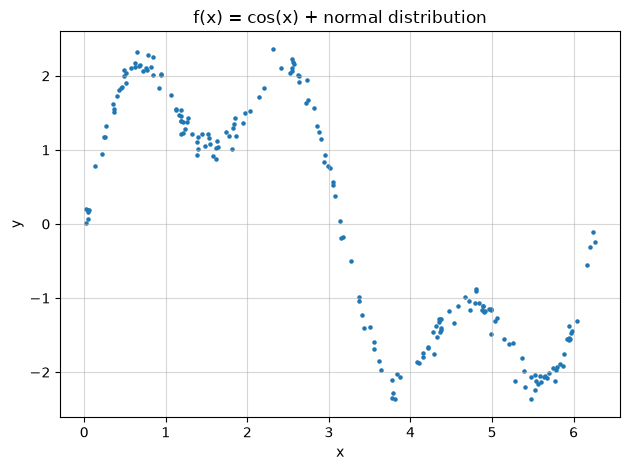

In [3]:
samples = 200

rng = np.random.default_rng(seed = SEED)
x = np.sort(rng.random(samples) * np.pi * 2)
y = 2 * np.sin(x) + np.sin(3 * x) + rng.normal(loc = 0, scale = 0.1, size = len(x))
#y = np.sin(x) + rng.normal(loc = 0, scale = 0.2, size = len(x))

df = pd.DataFrame(data = zip(x, y), columns = ['x', 'y'])

print("SSE:", round(calculador_sse(df), 2))

plt.title(label = "f(x) = cos(x) + normal distribution")
plt.scatter(df['x'], df['y'], s = 5)
plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')
plt.grid(alpha = 0.5)
plt.tight_layout()
plt.show()

In [4]:
def cond_min_max(lista_condicoes, j):
    cond_min = lista_condicoes[j - 1]
    cond_max = lista_condicoes[j]
    return cond_min, cond_max

def filtro(df, cond_min, cond_max):
    if any(df['x'] == cond_min):
        indice = np.where(df['x'] == cond_min)[0][0]
        if indice > 0:
            cond_min = df['x'].iloc[(indice - 1):(indice + 1)].mean()
        else:
            cond_min -= 0.01

    df_filtered = df[
        (cond_min < df['x']) &
        (df['x'] <= cond_max)
    ]
    
    return df_filtered

In [29]:
profundidade = 8

if profundidade < samples:

    lista_condicoes = [
        float(df['x'].min() - 0.1),
        float(df['x'].max() + 0.1)
    ]
    for i in tqdm(range(profundidade)):
        
        lista_resultados = []
        lista_medias = []
        for j in range(1, len(lista_condicoes)):
            cond_min, cond_max = cond_min_max(lista_condicoes, j)
            df_filtered = filtro(df, cond_min, cond_max)
            
            df_calculado = calcular_tabela(df_filtered)
            
            if not df_calculado.empty:
                lista_medias.append(float(df_calculado['media'].iloc[0]))
            else:
                raise ValueError("Dataframe vazio")

            media_esquerda = float(df_calculado['media_esquerda'].iloc[0])
            media_direita = float(df_calculado['media_direita'].iloc[0])

            lista_resultados.append(media_esquerda)
            lista_resultados.append(media_direita)

        lista_condicoes.extend(lista_medias)
        lista_condicoes = list(sorted(lista_condicoes))

else:
    raise ValueError(f"A profundidade deve ser menor que {samples}")

condicoes = []
for i in range(1, len(lista_condicoes)):
    resultado = (lista_condicoes[i - 1] <= x) & (x < lista_condicoes[i])
    condicoes.append(resultado)

mask = np.select(condicoes, lista_resultados)

100%|██████████| 8/8 [00:01<00:00,  7.53it/s]


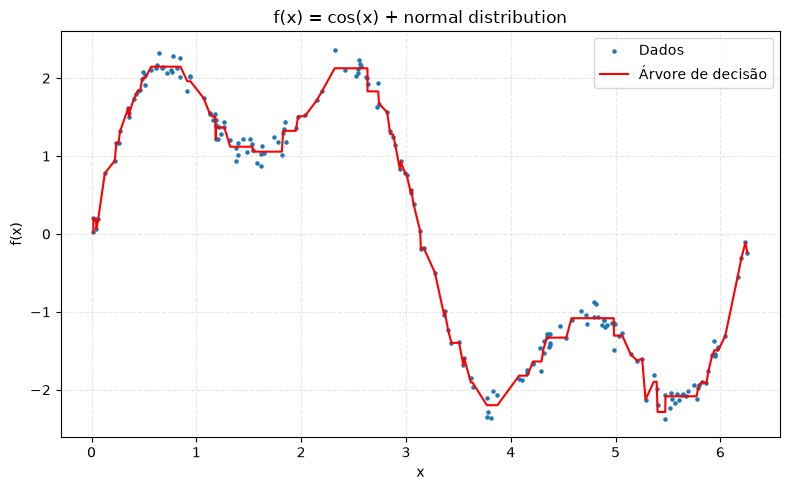

In [34]:
fig, ax = plt.subplots(figsize = (8, 5))

plt.title(label = "f(x) = cos(x) + normal distribution")

plt.scatter(x, y, s = 5, label = 'Dados')
plt.plot(x, mask, color = 'red', label = 'Árvore de decisão')

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'f(x)')
plt.grid(alpha = 0.3, ls = '--')
plt.tight_layout()
plt.legend()
plt.show()

### Procurando a primeira divisão

In [9]:
df_aux = calcular_tabela(df)
df_aux_filtered = df_aux[df_aux['sse_total'] == df_aux['sse_total'].min()]
df_aux_filtered

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
104,3.138851,35.140789,25.47536,60.616149,1.439848,-1.513373


-0.294858796685147
6.568779717164811


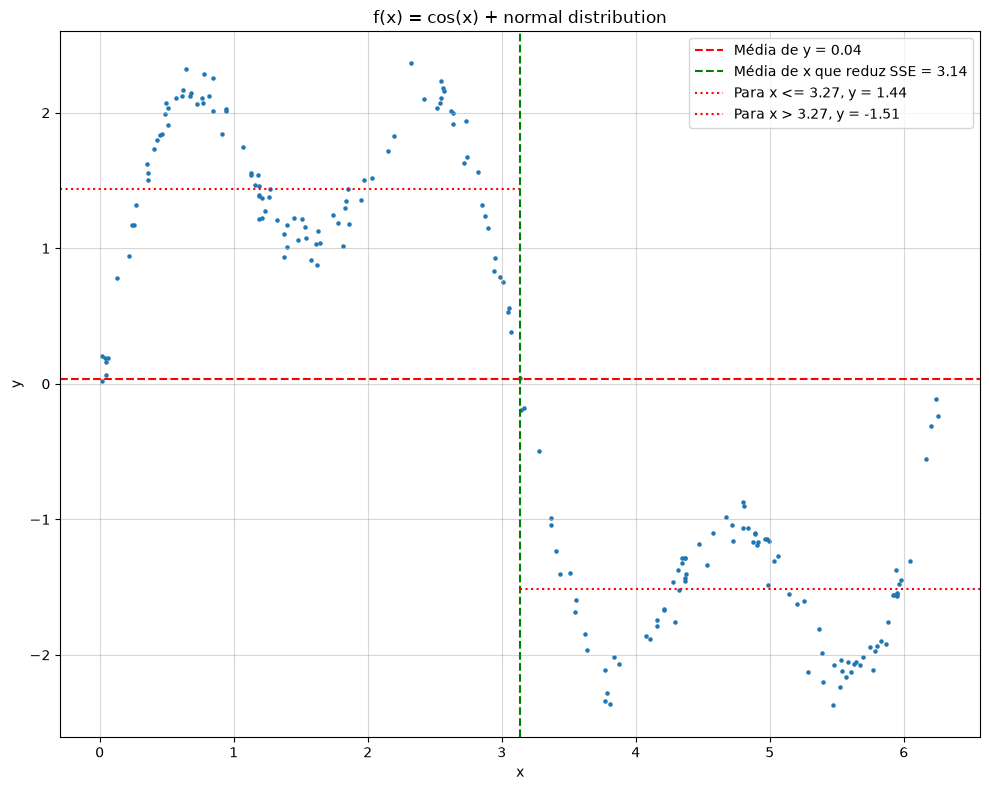

In [10]:
fig, ax = plt.subplots(figsize = (10, 8))

plt.title(label = "f(x) = cos(x) + normal distribution")
plt.scatter(x, y, s = 5)

valor = df['y'].mean()
plt.axhline(
    y = valor, 
    color = 'r', 
    ls = '--', 
    label = f'Média de y = {round(valor, 2)}'
)

valor = df_aux_filtered.iloc[0]['media']
plt.axvline(
    x = valor, 
    color = 'g', 
    ls = '--', 
    label = f'Média de x que reduz SSE = {round(valor, 2)}'
)

x_min, x_max = ax.get_xlim()

print(x_min)
print(x_max)

xmin = (df_aux_filtered['media'].iloc[0] - x_min) / (x_max - x_min)
xmax = (df_aux_filtered['media'].iloc[0] - x_min) / (x_max - x_min)

valor = df_aux_filtered['media_esquerda'].iloc[0]
plt.axhline(
    y = valor, 
    color = 'r', 
    ls = ':', 
    xmax=xmax,
    label = f"Para x <= 3.27, y = {round(valor, 2)}"
)

valor = df_aux_filtered['media_direita'].iloc[0]
plt.axhline(
    y = valor, color = 'r', ls = ':', xmin=xmin,
    label = f"Para x > 3.27, y = {round(valor, 2)}"
)

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')
plt.grid(alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

-0.294858796685147
6.568779717164811


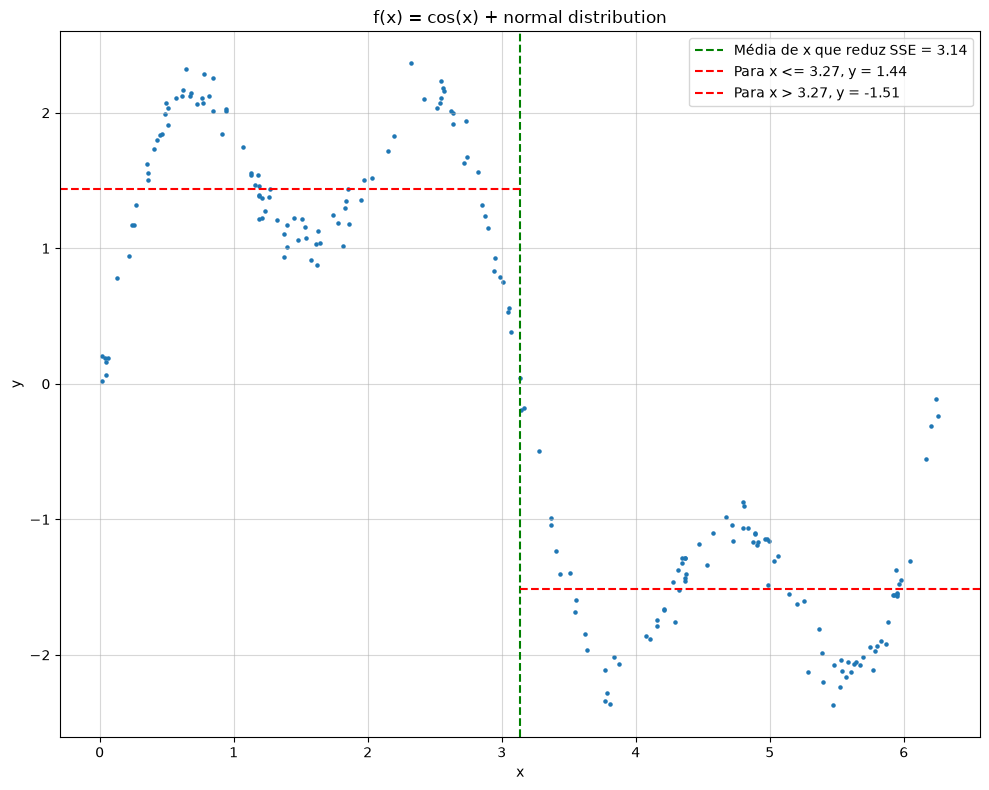

In [11]:
fig, ax = plt.subplots(figsize = (10, 8))

plt.title(label = "f(x) = cos(x) + normal distribution")
plt.scatter(x, y, s = 5)

valor = df['y'].mean()
# plt.axhline(
#     y = valor, 
#     color = 'r', 
#     ls = '--', 
#     label = f'Média de y = {round(valor, 2)}'
# )

valor = df_aux_filtered.iloc[0]['media']
plt.axvline(
    x = valor, 
    color = 'g', 
    ls = '--', 
    label = f'Média de x que reduz SSE = {round(valor, 2)}'
)

x_min, x_max = ax.get_xlim()

print(x_min)
print(x_max)

xmin = (df_aux_filtered['media'].iloc[0] - x_min) / (x_max - x_min)
xmax = (df_aux_filtered['media'].iloc[0] - x_min) / (x_max - x_min)

valor = df_aux_filtered['media_esquerda'].iloc[0]
plt.axhline(
    y = valor, 
    color = 'r', 
    ls = '--', 
    xmax=xmax,
    label = f"Para x <= 3.27, y = {round(valor, 2)}"
)

valor = df_aux_filtered['media_direita'].iloc[0]
plt.axhline(
    y = valor, color = 'r', ls = '--', xmin=xmin,
    label = f"Para x > 3.27, y = {round(valor, 2)}"
)

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')
plt.grid(alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

In [12]:
div = df_aux_filtered['media'].iloc[0]
df_2_esquerda = df[df['x'] <= div]
df_2_direita = df[df['x'] > div]

In [13]:
df_aux_filtered

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
104,3.138851,35.140789,25.47536,60.616149,1.439848,-1.513373


In [14]:
df_aux_2_esquerda = calcular_tabela(df_2_esquerda)

mask = df_aux_2_esquerda['sse_total'] == df_aux_2_esquerda['sse_total'].min()
df_aux_2_esquerda = df_aux_2_esquerda[mask]
df_aux_2_esquerda

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
6,0.174091,0.380071,23.787286,24.167356,0.230251,1.526247


In [15]:
df_aux_2_direita = calcular_tabela(df_2_direita)

mask = df_aux_2_direita['sse_total'] == df_aux_2_direita['sse_total'].min()
df_aux_2_direita = df_aux_2_direita[mask]
df_aux_2_direita

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
90,6.10505,19.256797,0.1034,19.360197,-1.566565,-0.30324


In [16]:
conditions = [
    x <= 0.477875,
    (0.477875 < x) & (x <= 3.266094),
    (3.266094 < x) & (x <= 5.732367),
    (5.732367 < x) & (x <= np.inf),
]

results = [
    0.20322,
    0.694375,
    -0.760247,
    -0.20639
    
]

mask = np.select(conditions, results)

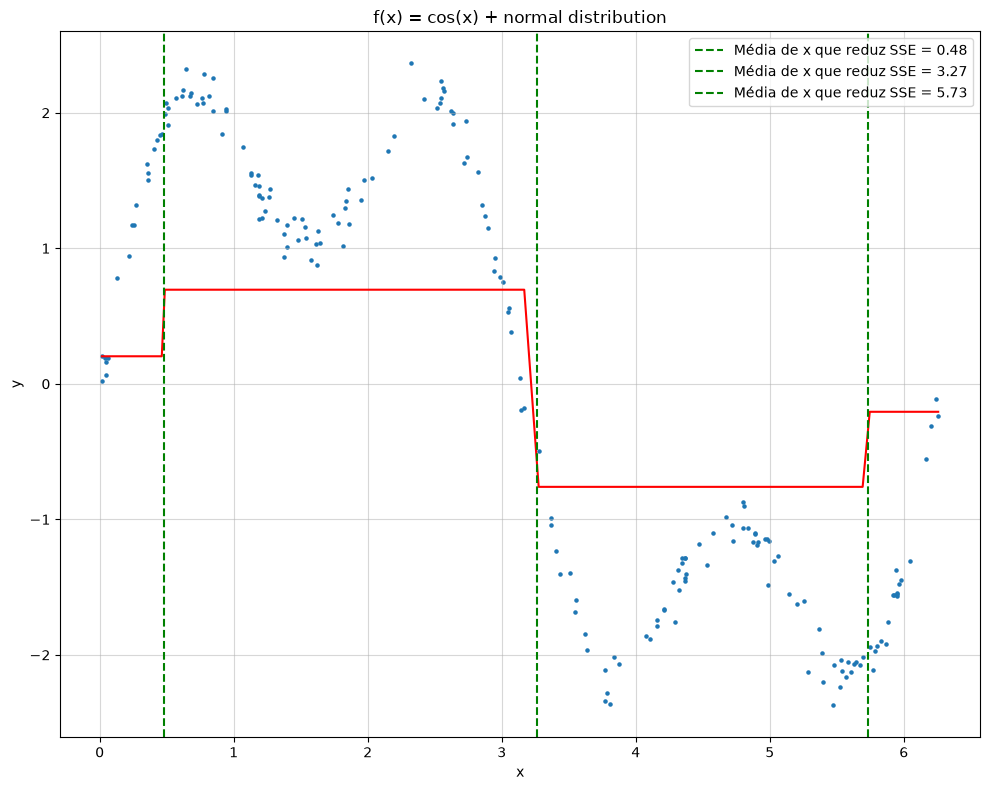

In [17]:
fig, ax = plt.subplots(figsize = (10, 8))

plt.title(label = "f(x) = cos(x) + normal distribution")
plt.scatter(x, y, s = 5)

plt.plot(x, mask, color = 'red')

valor = 0.477875
plt.axvline(
    x = valor, 
    color = 'g', 
    ls = '--', 
    label = f'Média de x que reduz SSE = {round(valor, 2)}'
)

valor = 3.266094
plt.axvline(
    x = valor, 
    color = 'g', 
    ls = '--', 
    label = f'Média de x que reduz SSE = {round(valor, 2)}'
)

valor = 5.732367
plt.axvline(
    x = valor, 
    color = 'g', 
    ls = '--', 
    label = f'Média de x que reduz SSE = {round(valor, 2)}'
)

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')
plt.grid(alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

In [18]:
div = df_aux_filtered['media'].iloc[0]
df_2_esquerda = df[df['x'] <= div]
df_2_direita = df[df['x'] > div]

In [19]:
df_aux_filtered

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
104,3.138851,35.140789,25.47536,60.616149,1.439848,-1.513373


In [20]:
df_aux_2_esquerda = calcular_tabela(df_2_esquerda)

mask = df_aux_2_esquerda['sse_total'] == df_aux_2_esquerda['sse_total'].min()
df_aux_2_esquerda = df_aux_2_esquerda[mask]
df_aux_2_esquerda

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
6,0.174091,0.380071,23.787286,24.167356,0.230251,1.526247


In [21]:
df_aux_2_direita = calcular_tabela(df_2_direita)

mask = df_aux_2_direita['sse_total'] == df_aux_2_direita['sse_total'].min()
df_aux_2_direita = df_aux_2_direita[mask]
df_aux_2_direita

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
90,6.10505,19.256797,0.1034,19.360197,-1.566565,-0.30324


In [22]:
conditions = [
    x <= 0.477875,
    (0.477875 < x) & (x <= 3.266094),
    (3.266094 < x) & (x <= 5.732367),
    (5.732367 < x) & (x <= np.inf),
]

results = [
    0.20322,
    0.694375,
    -0.760247,
    -0.20639
]

mask = np.select(conditions, results)

In [23]:
mask = (3.266094 < df.x) & (df.x <= 5.732367)
df1 = calcular_tabela(df[mask])

mask = 5.732367 < df.x
df2 = calcular_tabela(df[mask])

display(df1)
display(df2)

,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
56,5.269837,8.608968,0.224879,8.833847,-1.434138,-2.094702


,media,sse_esquerda,sse_direita,sse_total,media_esquerda,media_direita
15,6.10505,0.92163,0.1034,1.02503,-1.682996,-0.30324


In [24]:
conditions = [
    x <= 0.229446,
    (0.229446 < x) & (x <= 0.477875),
    (0.477875 < x) & (x <= 2.468861),
    (2.468861 < x) & (x <= 3.266094),
    (3.266094 < x) & (x <= 3.969393),
    (3.969393 < x) & (x <= 5.732367),
    (5.732367 < x) & (x <= 6.071574),
    (6.071574 < x) & (x <= np.inf),
]

results = [
    0.018176,
    0.342002,
    0.868602,
    0.29614,
    -0.395986,
    -0.876811,
    -0.362746,
    -0.089124
]

mask = np.select(conditions, results)

C:\Users\AriosvaldoBarros\AppData\Local\Temp\ipykernel_53356\2972121152.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


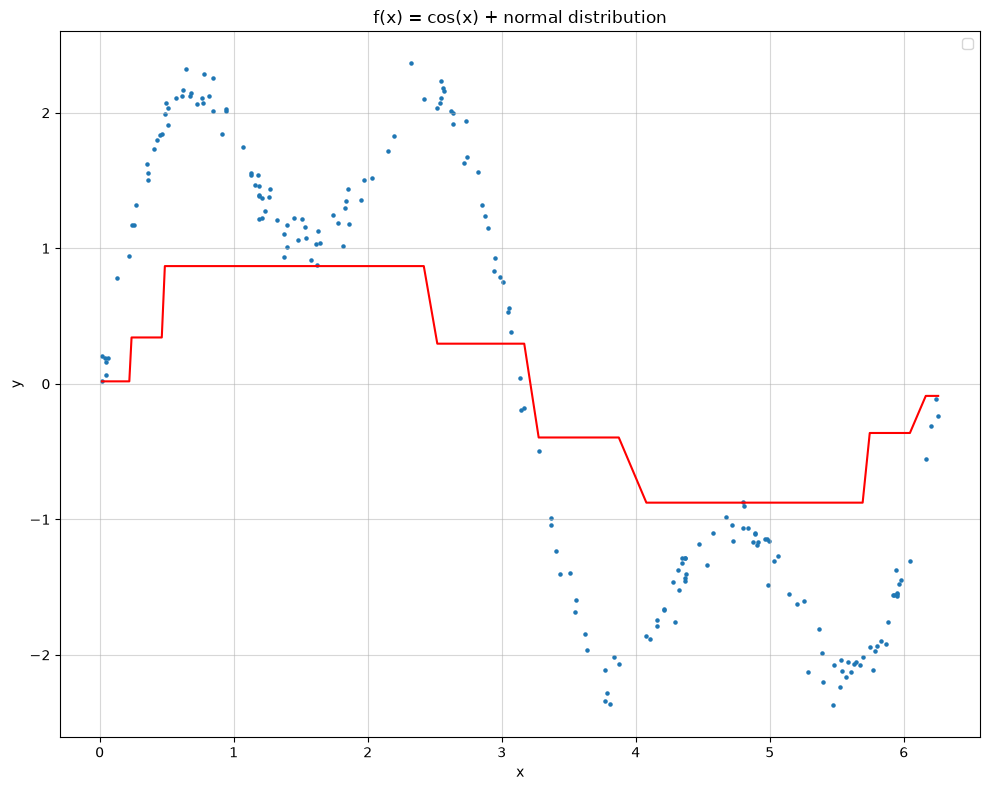

In [25]:
fig, ax = plt.subplots(figsize = (10, 8))

plt.title(label = "f(x) = cos(x) + normal distribution")
plt.scatter(x, y, s = 5)

plt.plot(x, mask, color = 'red')

plt.xlabel(xlabel = 'x')
plt.ylabel(ylabel = 'y')
plt.grid(alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

## Poder dos weak lerners

100%|██████████| 10/10 [00:00<00:00, 18.83it/s]


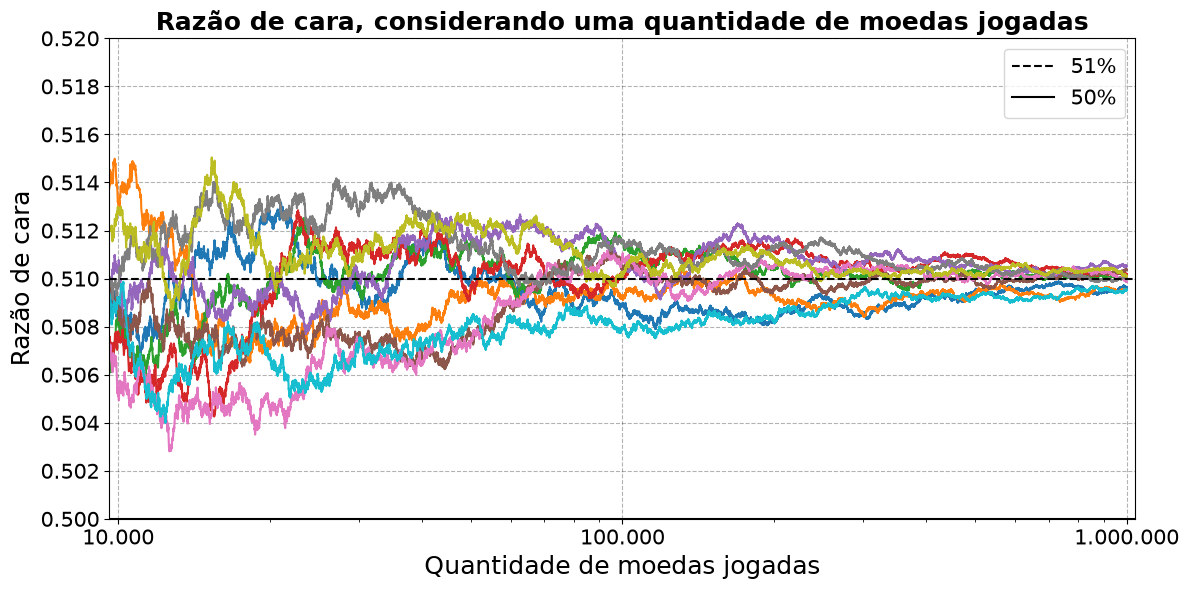

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Quantidade de moedas jogadas
n = 1_000_000

# Probabilidade de dar cara
percentual_base = 51

# Quantidade de simulações
qtd_curvas = 10


# Define o tamanho do gráfico
plt.figure(figsize=(12, 6))

# Define um título para o gráfico
plt.title("Razão de cara, considerando uma quantidade de moedas jogadas", fontsize = 18, fontweight='bold')

for i in tqdm(range(qtd_curvas)):

    rng = np.random.default_rng(seed = i)
    result = rng.random(size = (n))
    df_aux = pd.DataFrame(data = {'result': result})
    df_aux['probability'] = percentual_base / 100
    df_aux['event'] = np.where(df_aux['result'] >= (1 - df_aux['probability']), 1, 0)
    df_aux['event_sum'] = df_aux['event'].cumsum()
    df_aux.index = (df_aux.index + 1)
    df_aux['percentual'] = df_aux['event_sum'] / df_aux.index

    # Cria uma coluna de valores aleatórios e seleciona apenas um número específico
    # a ideia é reduzir a quantidade de dados, então se você gera números aleatórios de 0 até 19
    # e seleciona apenas o número 0, então você está reduzindo o dataframe em 20x
    df_aux['aleatorio'] = np.random.randint(0, 5, df_aux.shape[0])
    df_aux = df_aux[df_aux['aleatorio'] == 0]

    plt.plot(df_aux.index, df_aux.percentual)

plt.ylabel("Razão de cara", fontsize = 18)
plt.yticks(ticks = np.arange(0, 1, 0.002), fontsize = 15)
plt.ylim(top = 0.52, bottom = 0.50)

plt.xlabel("Quantidade de moedas jogadas", fontsize = 18)
plt.xscale('log', base = 10)
plt.xticks(
    [10_000, 100_000, 1_000_000], 
    ['10.000', '100.000', '1.000.000'], fontsize = 15
)
plt.xlim(left = 10_000 *0.96, right = 1_000_000 * 1.04)

plt.axhline(y = 0.51, ls = '--', color = 'black', label = '51%')
plt.axhline(y = 0.5, ls = '-', color = 'black', label = '50%')

plt.grid(alpha = 0.3, ls = '--', color = 'black')

# Cria e define o tamanho da fonte da legenda
plt.legend(fontsize = 15)

# Reduz a quantidade de espaço em branco na parte mais externa da imagem
plt.tight_layout()


# Nome da imagem que serrrá salva
file_name = 'weak_learners.png'

# Salva a imagem
plt.savefig(fname = file_name, dpi = 300, bbox_inches = "tight")


plt.show()

In [76]:
import numpy as np
import pandas as pd
from math import factorial

#========================================

def coeficiente_binomial(k, N):
    """Calcula o coeficiente binomial."""
    return (factorial(N) / (factorial(N - k) * factorial(k)))

def calculo_probabilidade(k, N, p):
    """Calcula a probabilidade."""
    return coeficiente_binomial(k, N) * (p ** k) * ((1 - p) ** (N - k))

def gerar_tabela_equacao(p, N):
    """Gera uma tabela estruturada com todas as probabilidades aplicando a equação."""
    lista = []
    for i in range(N + 1):
        lista.append((i, calculo_probabilidade(i, N, p) * 100))

    # Cria a tabela
    df = pd.DataFrame(
        data = lista, 
        columns = ["acertos", 'probabilidade']
    )

    # Probabilidade acumulada desconsiderando a probabildiade 0
    df['probabilidade_acumulada'] = df['probabilidade'].cumsum() - df.loc[0, 'probabilidade']

    # Arredonda os valores das colunas flutuantes
    float_cols = df.select_dtypes(include="float").columns
    df[float_cols] = df[float_cols].round(2)

    return df
    
#========================================

# Probabilidade do evento ocorrer
p = 0.51

# Quantidade de tentativas
N = 10

df_formula = gerar_tabela_equacao(p, N)

display(df_formula)

,acertos,probabilidade,probabilidade_acumulada
0,0,0.08,0.00
1,1,0.83,0.83
2,2,3.89,4.72
3,3,10.80,15.52
4,4,19.66,35.18
5,5,24.56,59.74
6,6,21.30,81.04
7,7,12.67,93.71
8,8,4.94,98.66
9,9,1.14,99.80
